# Neural Spike Sorting with PCA and Gaussian Mixtures

An electrode in the brain records the electrical spikes of several nearby neurons at once. **Spike sorting** works out which spikes came from which neuron, using only the shape of each waveform.

This notebook sorts 3,298 recorded spikes (70 voltage samples each) with no labels. It compresses the waveforms with PCA, clusters them with a Gaussian mixture model, picks the number of neurons with BIC and a stability test, and profiles each putative neuron by its waveform shape.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
UNIT_COLORS = ['#2a78d6', '#eb6834', '#1baf7a']   # colour-blind-checked palette
UNIT_MARKERS = ['o', 's', '^']
RNG = np.random.default_rng(0)

# The file stores one spike per column; transpose to one spike per row.
X = np.loadtxt('../data/spikes.csv', delimiter=',').T
n_spikes, n_samples = X.shape
print(f'{n_spikes:,} spikes × {n_samples} voltage samples')


3,298 spikes × 70 voltage samples


## 1. What the raw waveforms look like

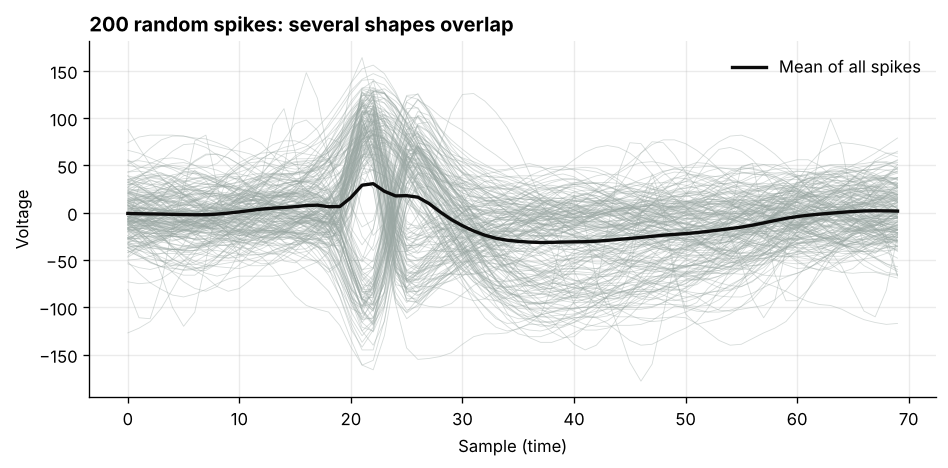

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
idx = RNG.choice(n_spikes, 200, replace=False)
ax.plot(X[idx].T, color='#9aa7a3', lw=0.5, alpha=0.4)
ax.plot(X.mean(0), color='#0b0b0b', lw=2, label='Mean of all spikes')
ax.set_xlabel('Sample (time)'); ax.set_ylabel('Voltage')
ax.set_title('200 random spikes: several shapes overlap', loc='left', fontweight='bold')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()


## 2. Compressing the waveforms with PCA

Each spike is a point in 70 dimensions, but neighbouring samples are highly correlated. PCA finds the few directions that carry most of the variation.


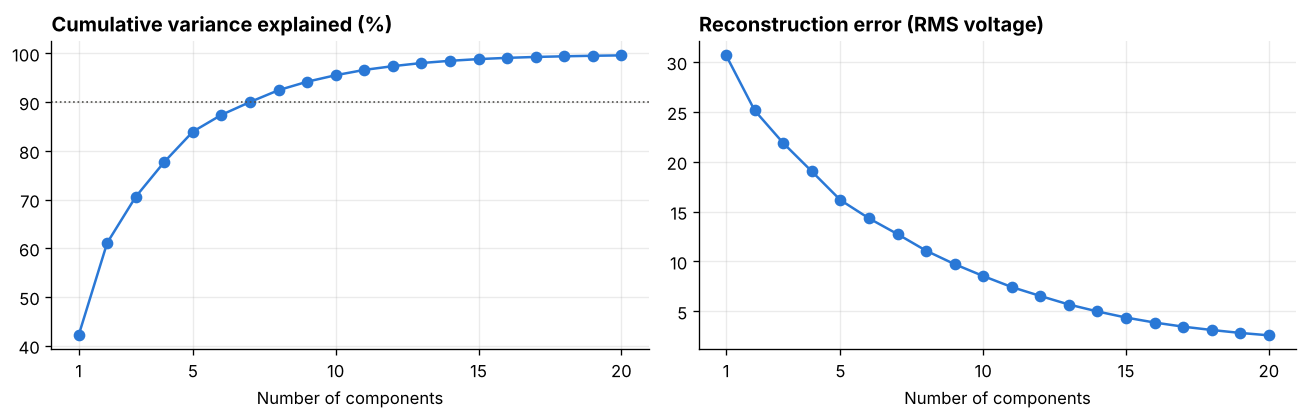

 2 components keep 61% of the variance
 3 components keep 71% of the variance
 5 components keep 84% of the variance
10 components keep 96% of the variance
Components needed for 90%: 7, for 95%: 10


In [3]:
pca_full = PCA().fit(X)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
ks = np.arange(1, 21)
recon_rmse = []
for k in ks:
    p = PCA(k).fit(X)
    recon_rmse.append(np.sqrt(np.mean((X - p.inverse_transform(p.transform(X))) ** 2)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ks, 100 * cumvar[:20], marker='o', color='#2a78d6')
axes[0].axhline(90, color='#52514e', ls=':', lw=1)
axes[0].set_title('Cumulative variance explained (%)', loc='left', fontweight='bold')
axes[1].plot(ks, recon_rmse, marker='o', color='#2a78d6')
axes[1].set_title('Reconstruction error (RMS voltage)', loc='left', fontweight='bold')
for ax in axes: ax.set_xlabel('Number of components'); ax.set_xticks([1, 5, 10, 15, 20])
plt.tight_layout(); plt.show()

for k in (2, 3, 5, 10):
    print(f'{k:>2} components keep {cumvar[k-1]:.0%} of the variance')
print(f'Components needed for 90%: {np.searchsorted(cumvar, 0.90) + 1}, for 95%: {np.searchsorted(cumvar, 0.95) + 1}')


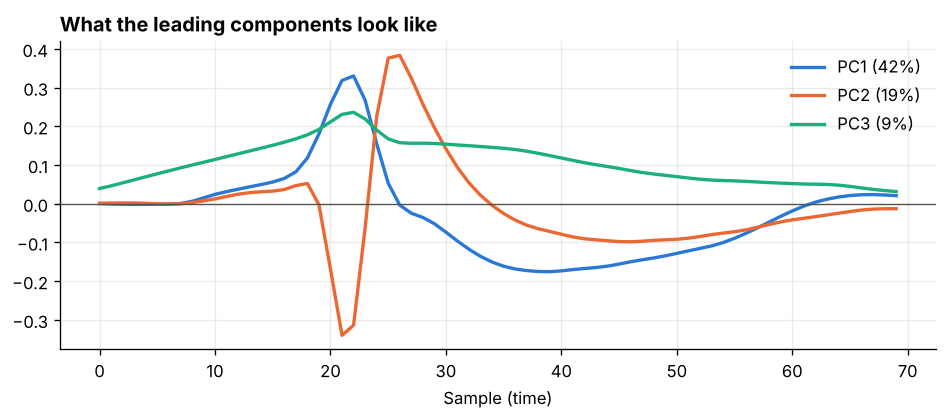

In [4]:
# The first three components as waveform shapes
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, c in enumerate(['#2a78d6', '#eb6834', '#1baf7a']):
    ax.plot(pca_full.components_[i], color=c, lw=2, label=f'PC{i+1} ({pca_full.explained_variance_ratio_[i]:.0%})')
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_xlabel('Sample (time)'); ax.set_title('What the leading components look like', loc='left', fontweight='bold')
ax.legend(frameon=False); plt.tight_layout(); plt.show()


## 3. How many neurons?

Spikes are clustered in the space of the first three components with a Gaussian mixture model. Two checks choose the number of clusters:

- **BIC** (lower is better) rewards fit but penalises extra clusters.
- **Stability:** refit on 30 random 80% subsamples and measure agreement with the full-data clustering (adjusted Rand index, where 1 is identical). Real neurons should come back every time; spurious splits should not.


 k        BIC  silhouette  stability (ARI)
 2    121,803       0.439            0.819
 3    120,298       0.555            0.998
 4    120,267       0.452            0.896
 5    120,216       0.452            0.770
 6    120,357       0.257            0.783


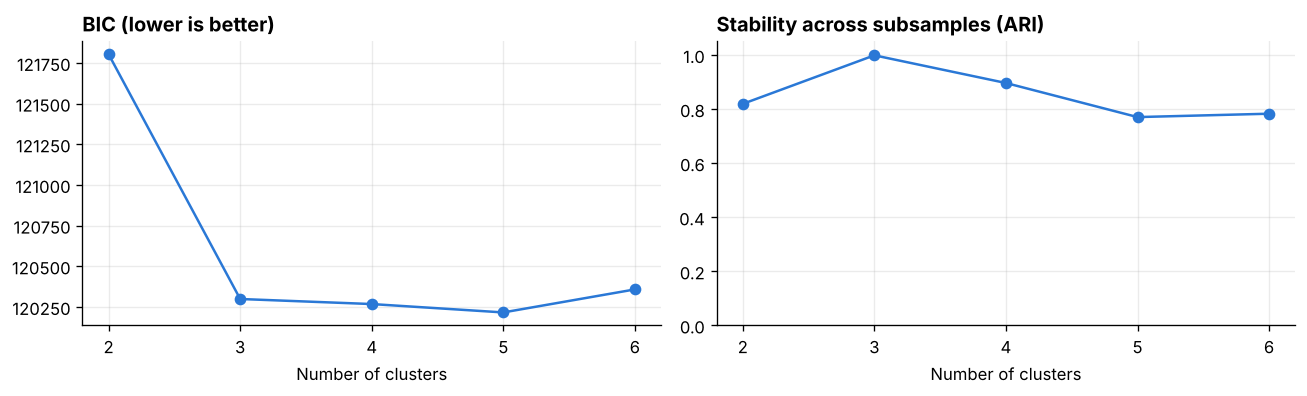

In [5]:
Z = PCA(3).fit_transform(X)
rows = []
for k in range(2, 7):
    gmm = GaussianMixture(k, n_init=5, random_state=0).fit(Z)
    labels = gmm.predict(Z)
    ari = []
    for i in range(30):
        sub = RNG.choice(n_spikes, int(0.8 * n_spikes), replace=False)
        refit = GaussianMixture(k, n_init=3, random_state=i).fit(Z[sub])
        ari.append(adjusted_rand_score(labels, refit.predict(Z)))
    rows.append((k, gmm.bic(Z), silhouette_score(Z, labels), np.mean(ari)))

print(f"{'k':>2} {'BIC':>10} {'silhouette':>11} {'stability (ARI)':>16}")
for k, bic, sil, ari in rows:
    print(f'{k:>2} {bic:>10,.0f} {sil:>11.3f} {ari:>16.3f}')

ks_ = [r[0] for r in rows]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(ks_, [r[1] for r in rows], marker='o', color='#2a78d6'); axes[0].set_title('BIC (lower is better)', loc='left', fontweight='bold')
axes[1].plot(ks_, [r[3] for r in rows], marker='o', color='#2a78d6'); axes[1].set_title('Stability across subsamples (ARI)', loc='left', fontweight='bold')
axes[1].set_ylim(0, 1.05)
for ax in axes: ax.set_xlabel('Number of clusters'); ax.set_xticks(ks_)
plt.tight_layout(); plt.show()


BIC improves sharply up to three clusters and then flattens, three clusters have the highest silhouette, and three is the only choice that is perfectly stable: extra clusters split real units differently on each subsample. **Three neurons** is the best-supported answer.

## 4. The sorted units

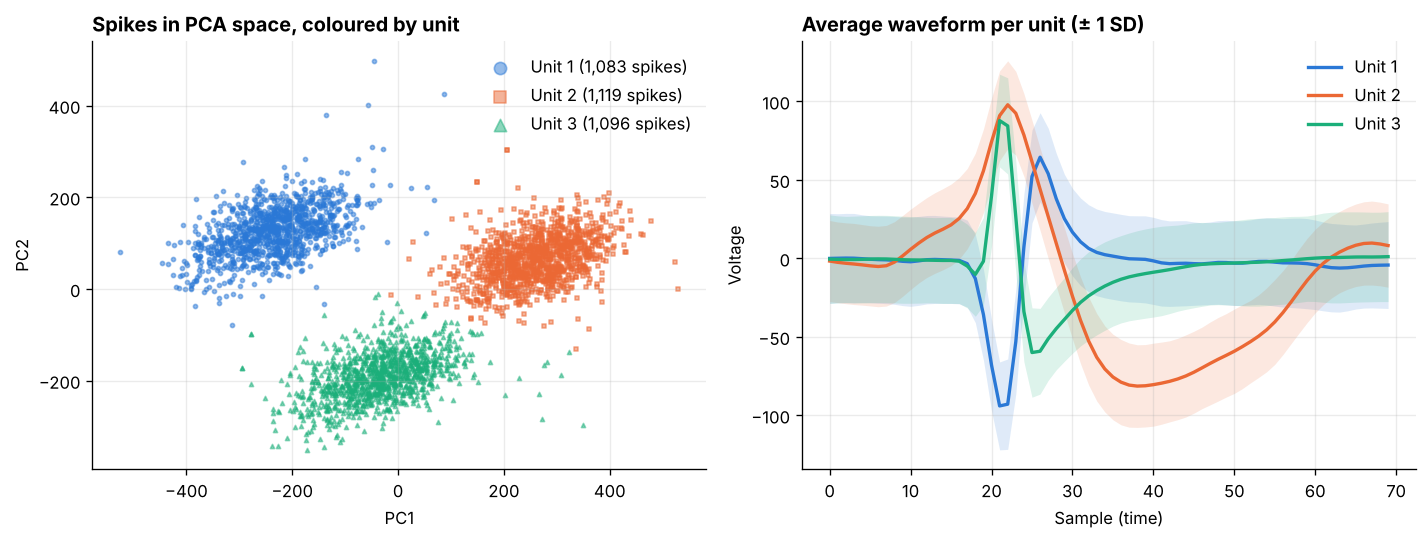

Spikes assigned with >95% confidence: 98.5%


In [6]:
K = 3
gmm = GaussianMixture(K, n_init=10, random_state=0).fit(Z)
labels = gmm.predict(Z)
# Order units by trough depth so colours are stable across runs
order = np.argsort([X[labels == c].mean(0).min() for c in range(K)])
labels = np.argsort(order)[labels]
confidence = gmm.predict_proba(Z).max(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for c in range(K):
    m = labels == c
    axes[0].scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.5, color=UNIT_COLORS[c], marker=UNIT_MARKERS[c], label=f'Unit {c+1} ({m.sum():,} spikes)')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].set_title('Spikes in PCA space, coloured by unit', loc='left', fontweight='bold')
axes[0].legend(frameon=False, markerscale=3)

t = np.arange(n_samples)
for c in range(K):
    w = X[labels == c]
    axes[1].fill_between(t, w.mean(0) - w.std(0), w.mean(0) + w.std(0), color=UNIT_COLORS[c], alpha=0.15, lw=0)
    axes[1].plot(t, w.mean(0), color=UNIT_COLORS[c], lw=2, label=f'Unit {c+1}')
axes[1].set_xlabel('Sample (time)'); axes[1].set_ylabel('Voltage')
axes[1].set_title('Average waveform per unit (± 1 SD)', loc='left', fontweight='bold')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.savefig('../assets/sorted_units.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Spikes assigned with >95% confidence: {np.mean(confidence > 0.95):.1%}')


In [7]:
print(f"{'Unit':<6}{'spikes':>8}{'trough':>9}{'peak':>8}{'trough→peak (samples)':>24}")
for c in range(K):
    w = X[labels == c].mean(0)
    print(f"{c+1:<6}{(labels == c).sum():>8,}{w.min():>9.1f}{w.max():>8.1f}{abs(int(w.argmax()) - int(w.argmin())):>24}")


Unit    spikes   trough    peak   trough→peak (samples)
1        1,083    -94.0    64.4                       5
2        1,119    -81.4    97.8                      16
3        1,096    -60.0    87.7                       4


## 5. Findings

- **Three distinct neurons.** The spikes split into three units of roughly equal size. The split is identical on every subsample, which is strong evidence that these are real units rather than artefacts of the algorithm.
- **Shape tells them apart.** Unit 1 has the classic shape: a deep, narrow trough followed by a peak. Units 2 and 3 are inverted, with the positive peak first. Of those two, Unit 3 is narrow (4 samples from peak to trough) while Unit 2 is broad, with a slow trough 16 samples after its peak. In real recordings, broad and narrow waveforms are often linked to different neuron types.
- **Few dimensions are enough.** Three principal components hold 71% of the variance and are enough to separate the units cleanly; 10 components are needed to keep 95% of it.

**Limitations.** There are no ground-truth labels, so the units are putative. A full spike-sorting pipeline would also check refractory-period violations using spike times, which this dataset does not include.
